In [2]:
import pandas as pd

# Qra l-fichier Excel
df = pd.read_excel("/kaggle/input/datasets/zakariaeelhaddouchi/datandr/NDR Eventlog-Export.xlsx")



In [8]:
!pip install hyperimpute openpyxl scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 92.9/92.9 kB 1.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.3/58.3 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.0/83.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 560.6/560.6 kB 5.3 MB/s eta 0:00:00a 0:00:01


In [3]:
df.isnull().sum()

Id               0
Timestamp        0
Date             0
Site             0
Host             0
Object           0
Property         0
Old_Value        0
Old_Message    202
New_Value        0
New_Message      0
dtype: int64

## Delete NUll value from df

In [9]:
from sklearn.preprocessing import OrdinalEncoder
from hyperimpute.plugins.imputers import Imputers

# 1. Khtar les colonnes li ghadi n-st3mlo f l-imputation
columns_to_use = ['Old_Value', 'New_Value', 'Old_Message', 'New_Message']
df_sub = df[columns_to_use].copy()

# 2. Encode text to numbers (kat-ḥawwel text l numbers)
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
encoded_data = encoder.fit_transform(df_sub.astype(str))

# 3. Rjja3 les NaNs l-blasshom (ḥith OrdinalEncoder kiy-ḥawwel NaNs l text)
import numpy as np
nan_mask = df_sub.isnull()
encoded_data[nan_mask] = np.nan

# 4. Khddam HyperImpute
imputer = Imputers().get("hyperimpute")
imputed_data = imputer.fit_transform(encoded_data)

# 5. Rjja3 l-numbers l-text l-aṣli
df_sub_imputed = encoder.inverse_transform(np.round(imputed_data))

# 6. Mjadjel l-colonne f df dialk l-aṣli
df['Old_Message'] = df_sub_imputed[:, 2]

print("Done! NaNs filled successfully.")
print("Remaining NaNs:", df['Old_Message'].isnull().sum())

Done! NaNs filled successfully.
Remaining NaNs: 0


In [12]:
df

,Id,Timestamp,Date,Site,Host,Object,Property,Old_Value,Old_Message,New_Value,New_Message
0,944894537,1785478581,"Jul 31, 06:16",ndr,NDR1GTV009,BGR,Status,-1,OK,-1,Online
1,944861992,1785477993,"Jul 31, 06:06",ndr,NDR1GTV009,BGR,Status,-1,Online,-1,OK
2,944705635,1785475264,"Jul 31, 05:21",ndr,NDR1CKB002,ATB,Status,5,Error,-1,OK
3,944695093,1785475111,"Jul 31, 05:18",ndr,NDR1CKB002,ATB,Status,-1,OK,5,Error
4,944633976,1785473931,"Jul 31, 04:58",ndr,NDR1CKB015,BTP,Status,-1,OK,-1,Online
...,...,...,...,...,...,...,...,...,...,...,...
15573,40491,1765807774,"Dec 15, 14:09",ndr,NDR1CKB018,BTP,Status,5,No Paper,-1,Online
15574,40509,1765807122,"Dec 15, 13:58",ndr,NDR1CKB009,BTP,Status,-1,Online,5,No Paper
15575,40506,1765807057,"Dec 15, 13:57",ndr,NDR1CKB009,ATB,Status,-1,OK,5,No Paper
15576,40478,1765806962,"Dec 15, 13:56",ndr,NDR1CKB003,ATB,Status,5,No Paper,-1,OK


In [13]:
# Sajjel l-Dataframe l-cleaned f fichier Excel jdid
df.to_excel("NDR_Eventlog_Cleaned.xlsx", index=False)

print("T-sajjel l-fichier f /kaggle/working/NDR_Eventlog_Cleaned.xlsx")

T-sajjel l-fichier f /kaggle/working/NDR_Eventlog_Cleaned.xlsx


In [15]:
import pandas as pd

# 1. REMOVING DUPLICATES (Izalat l-tikrar)
initial_rows = len(df)
df = df.drop_duplicates()
print(f"Removed {initial_rows - len(df)} duplicate rows.")

# 2. VALIDATING FORMATS & DATES (Tṣḥiḥ l-types dial l-data)
# L-colonne 'Date' rddha datetime format
# Tṣḥiḥ l-warning b تحديد l-format dial Date
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'], format='%b %d, %H:%M', errors='coerce')
# Clean text columns (Trim whitespaces & convert to uppercase/lowercase)
text_cols = ['Site', 'Host', 'Object', 'Property', 'Old_Message', 'New_Message']
for col in text_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()  # Mḥa l-massafat f l-awal/l-kher

# 3. NORMALIZING / CORRECTING ERRORS (Tṣḥiḥ l-a3dad)
# Convert numeric values to integer/float
num_cols = ['Old_Value', 'New_Value']
for col in num_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# 4. SAJJEL L-NATIJA L-NIHA'IYA
df.to_excel("NDR_Eventlog_Cleaned_Final.xlsx", index=False)
print("Data Cleaning & Transformation Complete! Saved to NDR_Eventlog_Cleaned_Final.xlsx")

Removed 0 duplicate rows.
Data Cleaning & Transformation Complete! Saved to NDR_Eventlog_Cleaned_Final.xlsx


## Monitoring & Data Quality Checks (Best Practice)

In [19]:

import pandas as pd
import numpy as np
from sklearn.preprocessing import OrdinalEncoder
from hyperimpute.plugins.imputers import Imputers

def extract_data(file_path: str) -> pd.DataFrame:
    """Extract: Read raw Excel file"""
    print(f"📥 Extracting data from {file_path}...")
    return pd.read_excel(file_path)

def transform_data(df: pd.DataFrame) -> pd.DataFrame:
    """Transform: Clean, Impute missing values & Format"""
    print("⚙️ Cleaning & Transforming data...")
    
    # 1. Duplicates
    df = df.drop_duplicates()
    
    # 2. Date Formatting
    if 'Date' in df.columns:
        df['Date'] = pd.to_datetime(df['Date'], format='%b %d, %H:%M', errors='coerce')
        
    # 3. String Stripping
    text_cols = ['Site', 'Host', 'Object', 'Property', 'Old_Message', 'New_Message']
    for col in text_cols:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip()
            
    # 4. Imputation using HyperImpute (if NaNs exist in Old_Message)
    if df['Old_Message'].isnull().sum() > 0:
        print("🩹 Running HyperImpute on missing values...")
        cols_to_encode = ['Old_Value', 'New_Value', 'Old_Message', 'New_Message']
        encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
        
        df_encoded = df[cols_to_encode].copy()
        encoded_matrix = encoder.fit_transform(df_encoded.astype(str))
        encoded_matrix[df_encoded.isnull()] = np.nan
        
        imputer = Imputers().get("hyperimpute")
        imputed_matrix = imputer.fit_transform(encoded_matrix)
        
        imputed_text = encoder.inverse_transform(np.round(imputed_matrix))
        df['Old_Message'] = imputed_text[:, 2]
        
    return df

def load_data(df: pd.DataFrame, output_path: str):
    """Load: Save processed data"""
    print(f"💾 Saving processed data to {output_path}...")
    df.to_excel(output_path, index=False)
    print("✅ Pipeline executed successfully!")

# Main Execution Function
def run_etl_pipeline(input_file: str, output_file: str):
    raw_df = extract_data(input_file)
    cleaned_df = transform_data(raw_df)
    load_data(cleaned_df, output_file)

# --- Test l-Pipeline ---
# run_etl_pipeline("/kaggle/input/.../NDR Eventlog-Export.xlsx", "NDR_Eventlog_Cleaned_Pipeline.xlsx")

In [24]:
df = pd.read_excel("/kaggle/input/datasets/zakariaeelhaddouchi/datandr/NDR Eventlog-Export.xlsx")

In [25]:
df.isnull().sum()

Id               0
Timestamp        0
Date             0
Site             0
Host             0
Object           0
Property         0
Old_Value        0
Old_Message    202
New_Value        0
New_Message      0
dtype: int64

In [26]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OrdinalEncoder
from hyperimpute.plugins.imputers import Imputers

# 1. Encode text columns to numeric values for HyperImpute
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
cols_to_encode = ['Old_Value', 'New_Value', 'Old_Message', 'New_Message']

df_encoded = df[cols_to_encode].copy()
encoded_matrix = encoder.fit_transform(df_encoded.astype(str))

# Put back NaNs where they originally were
encoded_matrix[df_encoded.isnull()] = np.nan

# 2. Run HyperImpute
imputer = Imputers().get("hyperimpute")
imputed_matrix = imputer.fit_transform(encoded_matrix)

# 3. Decode back to original text and fill 'Old_Message'
imputed_text = encoder.inverse_transform(np.round(imputed_matrix))
df['Old_Message'] = imputed_text[:, 2]

# 4. Final verification
print("--- Check missing values after imputation ---")
print(df.isnull().sum())

--- Check missing values after imputation ---
Id             0
Timestamp      0
Date           0
Site           0
Host           0
Object         0
Property       0
Old_Value      0
Old_Message    0
New_Value      0
New_Message    0
dtype: int64


In [27]:
df

,Id,Timestamp,Date,Site,Host,Object,Property,Old_Value,Old_Message,New_Value,New_Message
0,944894537,1785478581,"Jul 31, 06:16",ndr,NDR1GTV009,BGR,Status,-1,OK,-1,Online
1,944861992,1785477993,"Jul 31, 06:06",ndr,NDR1GTV009,BGR,Status,-1,Online,-1,OK
2,944705635,1785475264,"Jul 31, 05:21",ndr,NDR1CKB002,ATB,Status,5,Error,-1,OK
3,944695093,1785475111,"Jul 31, 05:18",ndr,NDR1CKB002,ATB,Status,-1,OK,5,Error
4,944633976,1785473931,"Jul 31, 04:58",ndr,NDR1CKB015,BTP,Status,-1,OK,-1,Online
...,...,...,...,...,...,...,...,...,...,...,...
15573,40491,1765807774,"Dec 15, 14:09",ndr,NDR1CKB018,BTP,Status,5,No Paper,-1,Online
15574,40509,1765807122,"Dec 15, 13:58",ndr,NDR1CKB009,BTP,Status,-1,Online,5,No Paper
15575,40506,1765807057,"Dec 15, 13:57",ndr,NDR1CKB009,ATB,Status,-1,OK,5,No Paper
15576,40478,1765806962,"Dec 15, 13:56",ndr,NDR1CKB003,ATB,Status,5,No Paper,-1,OK


# Save

In [28]:
# Sajjel l-Dataframe l-cleaned
df.to_excel("NDR_Eventlog_Cleaned_Final.xlsx", index=False)
df.to_csv("NDR_Eventlog_Cleaned_Final.csv", index=False)

print("✅ T-sajjel l-fichier b-najaḥ f /kaggle/working/!")

✅ T-sajjel l-fichier b-najaḥ f /kaggle/working/!


# Data Visualization : bch nfhmo data dylna

Date column is not in datetime format. Please parse dates first.


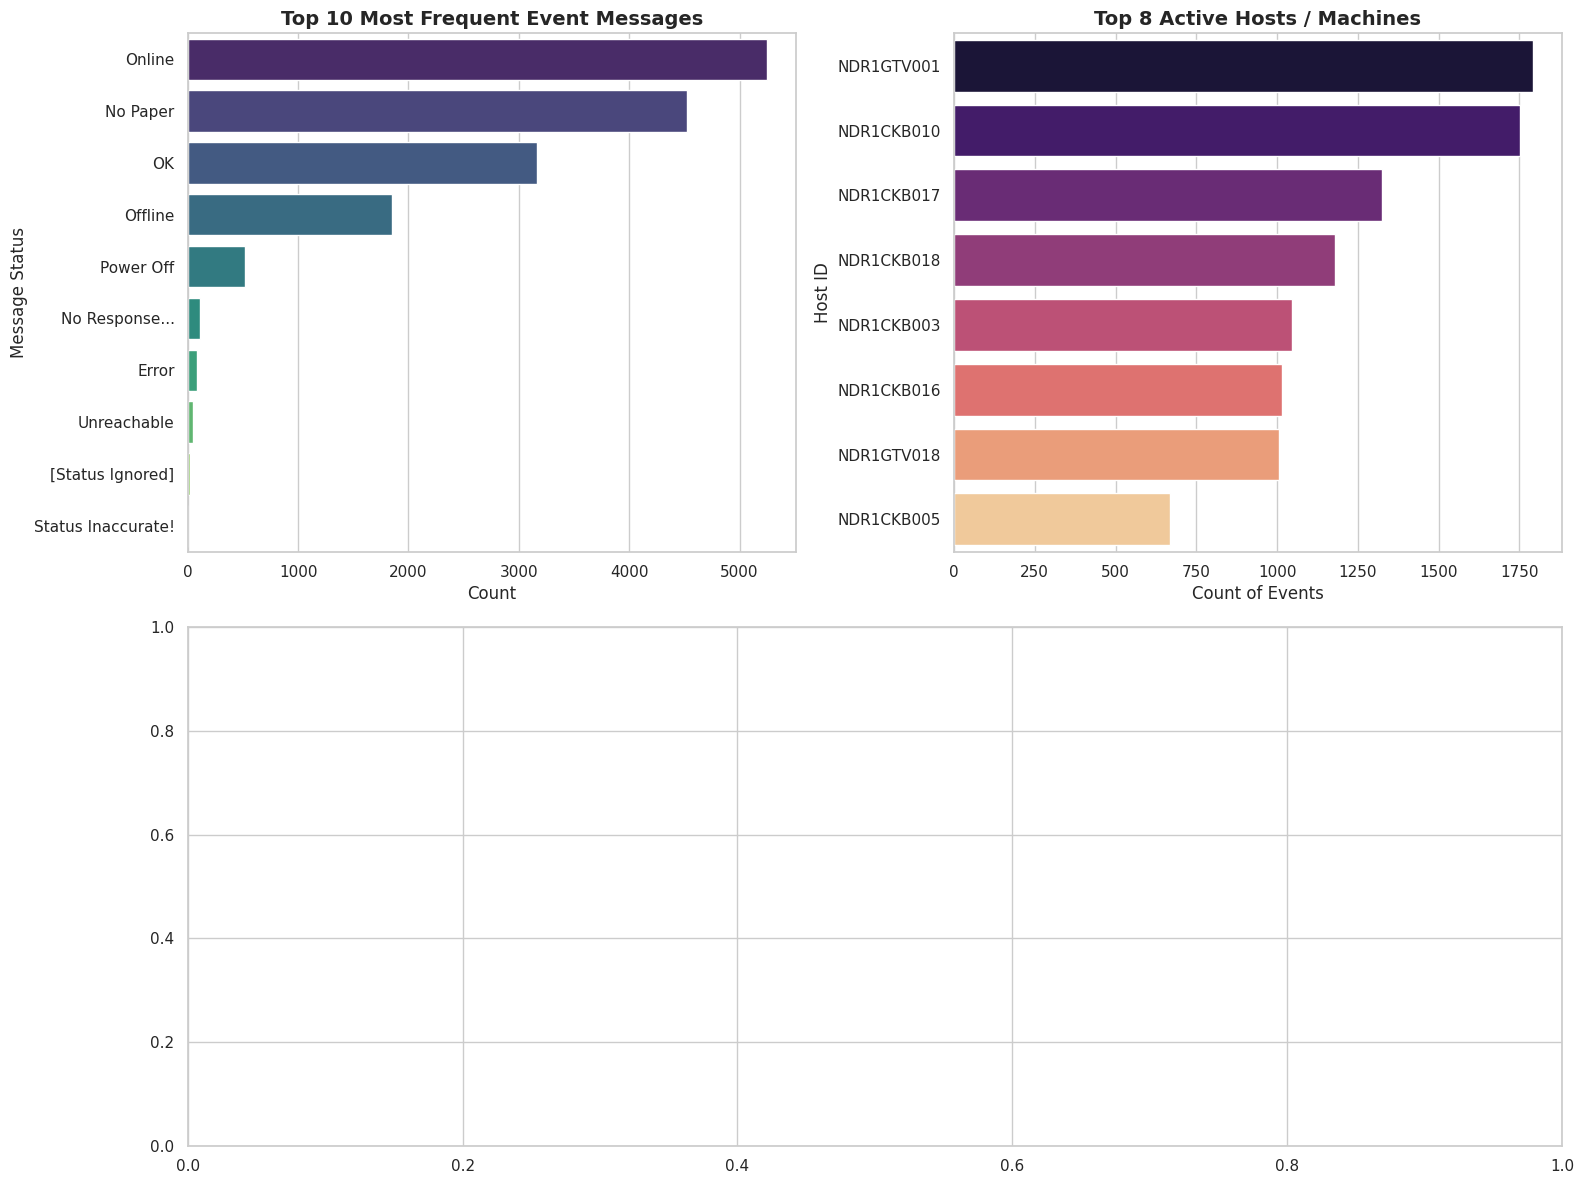

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for nice plots
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 12))

# ---------------------------------------------------------
# 1. Top 10 Most Frequent Messages (New_Message)
# ---------------------------------------------------------
plt.subplot(2, 2, 1)
top_messages = df['New_Message'].value_counts().head(10)
sns.barplot(
    x=top_messages.values, 
    y=top_messages.index, 
    hue=top_messages.index, 
    palette="viridis", 
    legend=False
)
plt.title("Top 10 Most Frequent Event Messages", fontsize=14, fontweight='bold')
plt.xlabel("Count")
plt.ylabel("Message Status")

# ---------------------------------------------------------
# 2. Activity Distribution by Host (Top Hosts)
# ---------------------------------------------------------
plt.subplot(2, 2, 2)
top_hosts = df['Host'].value_counts().head(8)
sns.barplot(
    x=top_hosts.values, 
    y=top_hosts.index, 
    hue=top_hosts.index, 
    palette="magma", 
    legend=False
)
plt.title("Top 8 Active Hosts / Machines", fontsize=14, fontweight='bold')
plt.xlabel("Count of Events")
plt.ylabel("Host ID")

# ---------------------------------------------------------
# 3. Temporal Patterns: Events Over Time (Hourly Distribution)
# ---------------------------------------------------------
plt.subplot(2, 1, 2)
if 'Date' in df.columns and pd.api.types.is_datetime64_any_dtype(df['Date']):
    # Extract Hour from Timestamp/Date
    df['Hour'] = df['Date'].dt.hour
    hourly_counts = df['Hour'].value_counts().sort_index()
    
    sns.lineplot(x=hourly_counts.index, y=hourly_counts.values, marker="o", color="crimson", linewidth=2.5)
    plt.title("Temporal Pattern: Activity Level by Hour of Day", fontsize=14, fontweight='bold')
    plt.xlabel("Hour of the Day (0 - 23)")
    plt.ylabel("Total Events")
    plt.xticks(range(0, 24))
else:
    print("Date column is not in datetime format. Please parse dates first.")

plt.tight_layout()
plt.show()

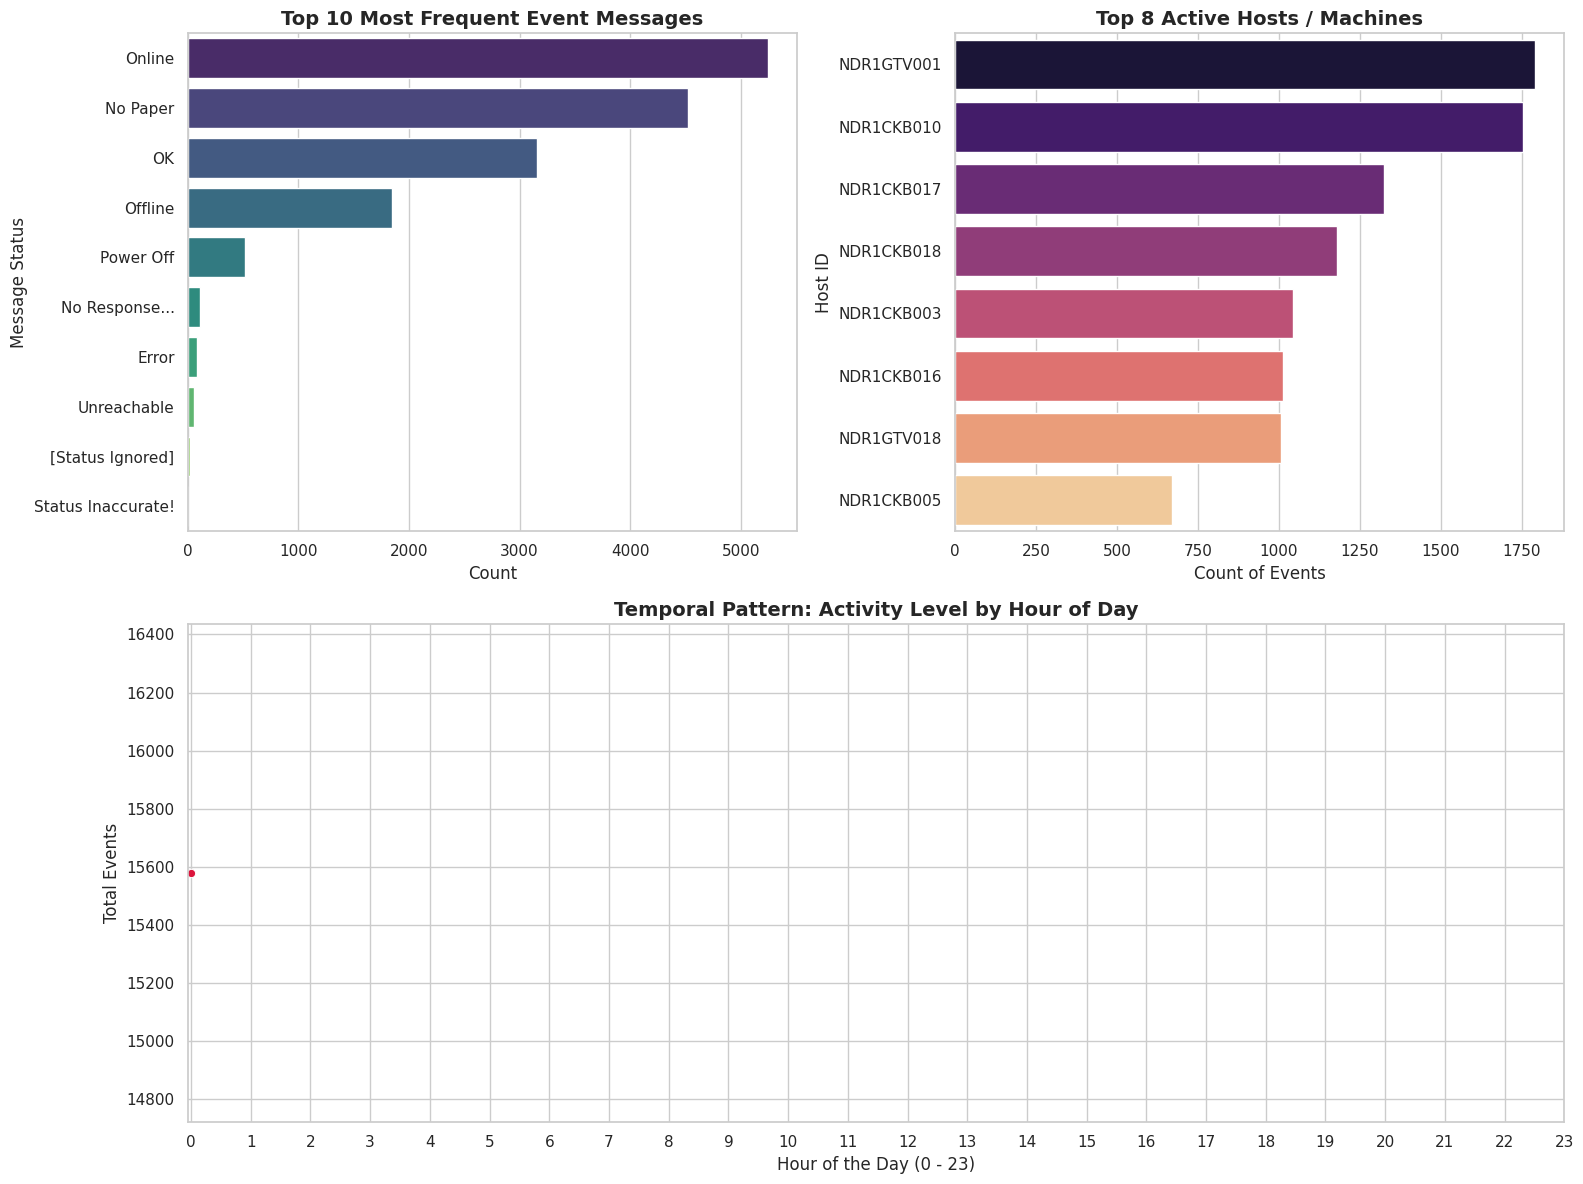

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Parsing safe dial Date (awla Timestamp ila kan 3ndk f l-df)
if 'Timestamp' in df.columns:
    df['Date'] = pd.to_datetime(df['Timestamp'], errors='coerce')
else:
    # Adding current year (2026) so pandas can parse "Jul 31, 06:16" correctly
    df['Date'] = pd.to_datetime("2026 " + df['Date'].astype(str), format='%Y %b %d, %H:%M', errors='coerce')

# Extract Hour
df['Hour'] = df['Date'].dt.hour

# Set style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 12))

# ---------------------------------------------------------
# 1. Top 10 Most Frequent Messages (New_Message)
# ---------------------------------------------------------
plt.subplot(2, 2, 1)
top_messages = df['New_Message'].value_counts().head(10)
sns.barplot(
    x=top_messages.values, 
    y=top_messages.index, 
    hue=top_messages.index, 
    palette="viridis", 
    legend=False
)
plt.title("Top 10 Most Frequent Event Messages", fontsize=14, fontweight='bold')
plt.xlabel("Count")
plt.ylabel("Message Status")

# ---------------------------------------------------------
# 2. Activity Distribution by Host (Top Hosts)
# ---------------------------------------------------------
plt.subplot(2, 2, 2)
top_hosts = df['Host'].value_counts().head(8)
sns.barplot(
    x=top_hosts.values, 
    y=top_hosts.index, 
    hue=top_hosts.index, 
    palette="magma", 
    legend=False
)
plt.title("Top 8 Active Hosts / Machines", fontsize=14, fontweight='bold')
plt.xlabel("Count of Events")
plt.ylabel("Host ID")

# ---------------------------------------------------------
# 3. Temporal Patterns: Events Over Time (Hourly Distribution)
# ---------------------------------------------------------
plt.subplot(2, 1, 2)
hourly_counts = df['Hour'].value_counts().sort_index()

if not hourly_counts.empty:
    sns.lineplot(x=hourly_counts.index, y=hourly_counts.values, marker="o", color="crimson", linewidth=2.5)
    plt.title("Temporal Pattern: Activity Level by Hour of Day", fontsize=14, fontweight='bold')
    plt.xlabel("Hour of the Day (0 - 23)")
    plt.ylabel("Total Events")
    plt.xticks(range(0, 24))
else:
    print("Warning: Could not extract hours. Check 'Timestamp' or 'Date' format.")

plt.tight_layout()
plt.show()

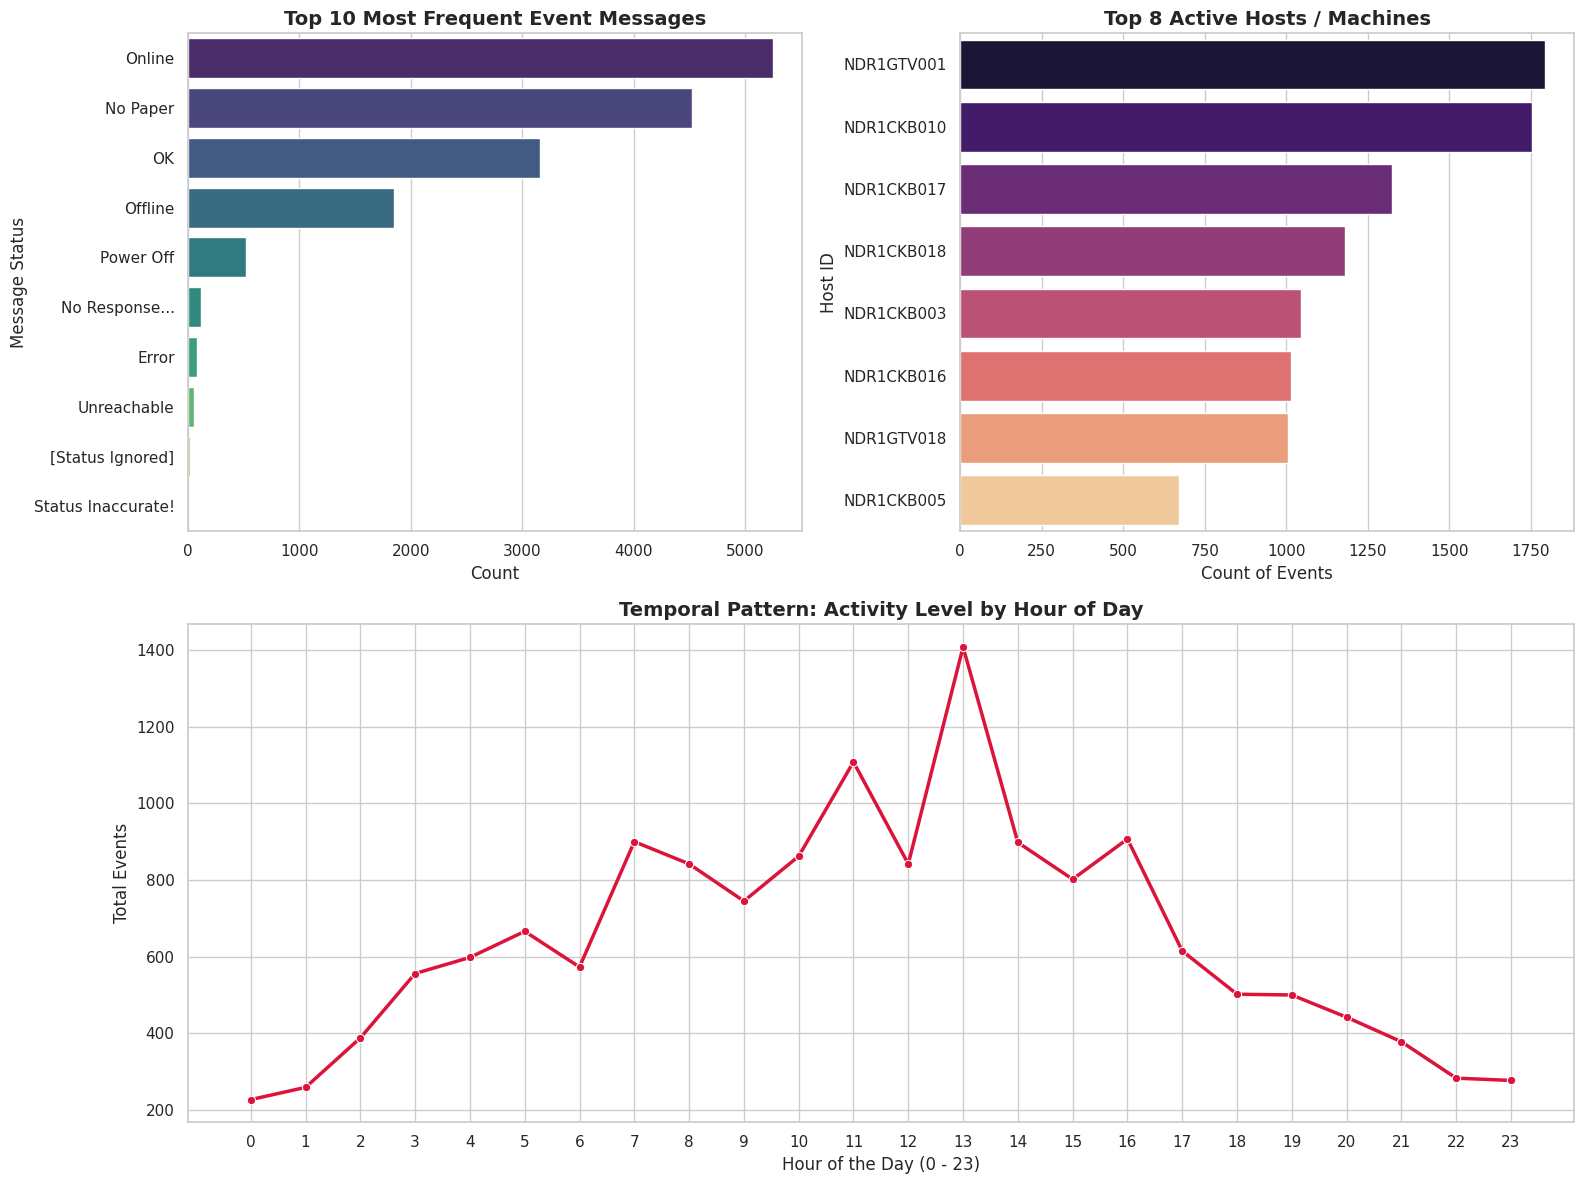

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Convert Timestamp properly from Epoch to Datetime
if 'Timestamp' in df.columns:
    df['Real_Date'] = pd.to_datetime(df['Timestamp'], unit='s', errors='coerce')
    df['Hour'] = df['Real_Date'].dt.hour
else:
    print("Timestamp column missing!")

# Set style for plots
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 12))

# ---------------------------------------------------------
# 1. Top 10 Most Frequent Messages
# ---------------------------------------------------------
plt.subplot(2, 2, 1)
top_messages = df['New_Message'].value_counts().head(10)
sns.barplot(
    x=top_messages.values, 
    y=top_messages.index, 
    hue=top_messages.index, 
    palette="viridis", 
    legend=False
)
plt.title("Top 10 Most Frequent Event Messages", fontsize=14, fontweight='bold')
plt.xlabel("Count")
plt.ylabel("Message Status")

# ---------------------------------------------------------
# 2. Activity Distribution by Host
# ---------------------------------------------------------
plt.subplot(2, 2, 2)
top_hosts = df['Host'].value_counts().head(8)
sns.barplot(
    x=top_hosts.values, 
    y=top_hosts.index, 
    hue=top_hosts.index, 
    palette="magma", 
    legend=False
)
plt.title("Top 8 Active Hosts / Machines", fontsize=14, fontweight='bold')
plt.xlabel("Count of Events")
plt.ylabel("Host ID")

# ---------------------------------------------------------
# 3. Temporal Patterns: Events Over Time (Hourly Distribution)
# ---------------------------------------------------------
plt.subplot(2, 1, 2)
hourly_counts = df['Hour'].value_counts().sort_index()

sns.lineplot(x=hourly_counts.index, y=hourly_counts.values, marker="o", color="crimson", linewidth=2.5)
plt.title("Temporal Pattern: Activity Level by Hour of Day", fontsize=14, fontweight='bold')
plt.xlabel("Hour of the Day (0 - 23)")
plt.ylabel("Total Events")
plt.xticks(range(0, 24))

plt.tight_layout()
plt.show()

# Vrai Panne

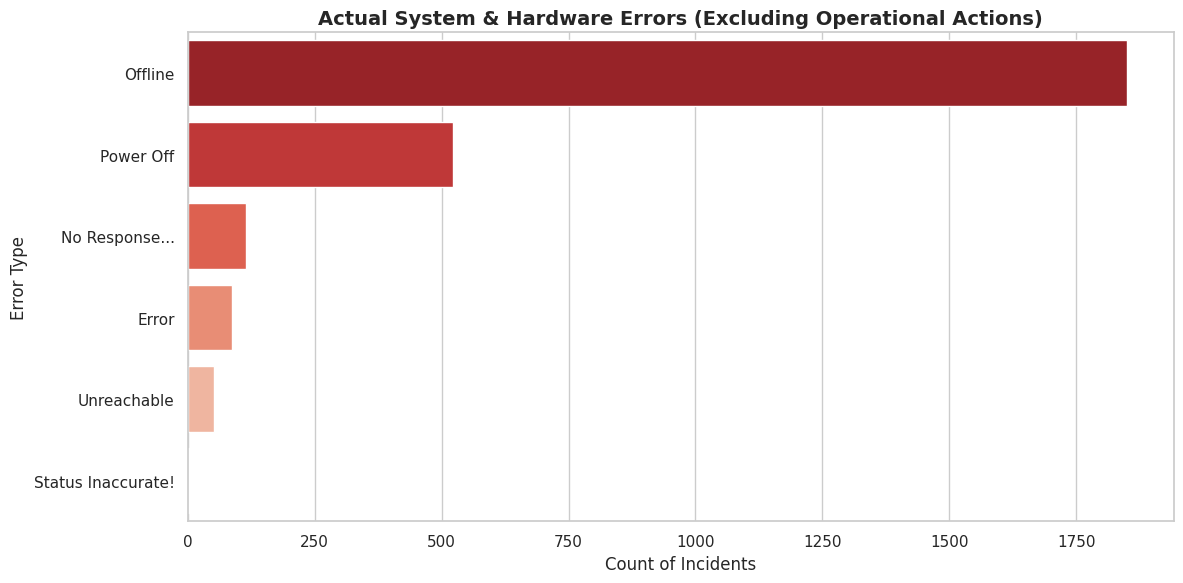

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filter out operational/normal statuses
normal_statuses = ['Online', 'OK', 'No Paper', '[Status Ignored]']
df_errors = df[~df['New_Message'].isin(normal_statuses)]

# 2. Plot Real Hardware/Network Errors
plt.figure(figsize=(12, 6))
error_counts = df_errors['New_Message'].value_counts()

sns.barplot(
    x=error_counts.values, 
    y=error_counts.index, 
    hue=error_counts.index, 
    palette="Reds_r", 
    legend=False
)

plt.title("Actual System & Hardware Errors (Excluding Operational Actions)", fontsize=14, fontweight='bold')
plt.xlabel("Count of Incidents")
plt.ylabel("Error Type")
plt.tight_layout()
plt.show()

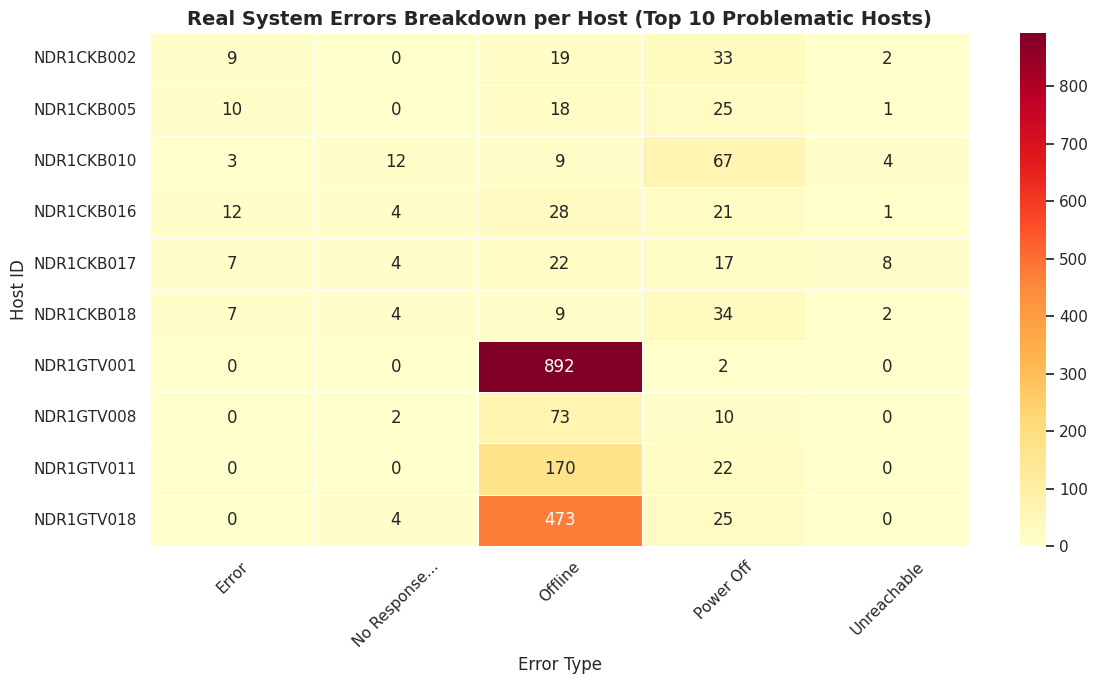

--- Top 5 Most Problematic Hosts (Total Real Errors) ---
Host
NDR1GTV001    894
NDR1GTV018    502
NDR1GTV011    192
NDR1CKB010     95
NDR1GTV008     85
Name: count, dtype: int64


In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Filter out normal operational statuses
normal_statuses = ['Online', 'OK', 'No Paper', '[Status Ignored]']
df_errors = df[~df['New_Message'].isin(normal_statuses)]

# 2. Get top 10 hosts with the highest number of actual errors
top_error_hosts = df_errors['Host'].value_counts().head(10).index
df_top_error_hosts = df_errors[df_errors['Host'].isin(top_error_hosts)]

# 3. Create Crosstab (Host vs Error Type)
error_pivot = pd.crosstab(df_top_error_hosts['Host'], df_top_error_hosts['New_Message'])

# 4. Plot Heatmap
plt.figure(figsize=(12, 7))
sns.heatmap(error_pivot, annot=True, fmt='d', cmap='YlOrRd', cbar=True, linewidths=0.5)

plt.title("Real System Errors Breakdown per Host (Top 10 Problematic Hosts)", fontsize=14, fontweight='bold')
plt.xlabel("Error Type")
plt.ylabel("Host ID")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Print Top 5 most problematic hosts overall
print("--- Top 5 Most Problematic Hosts (Total Real Errors) ---")
print(df_errors['Host'].value_counts().head(5))

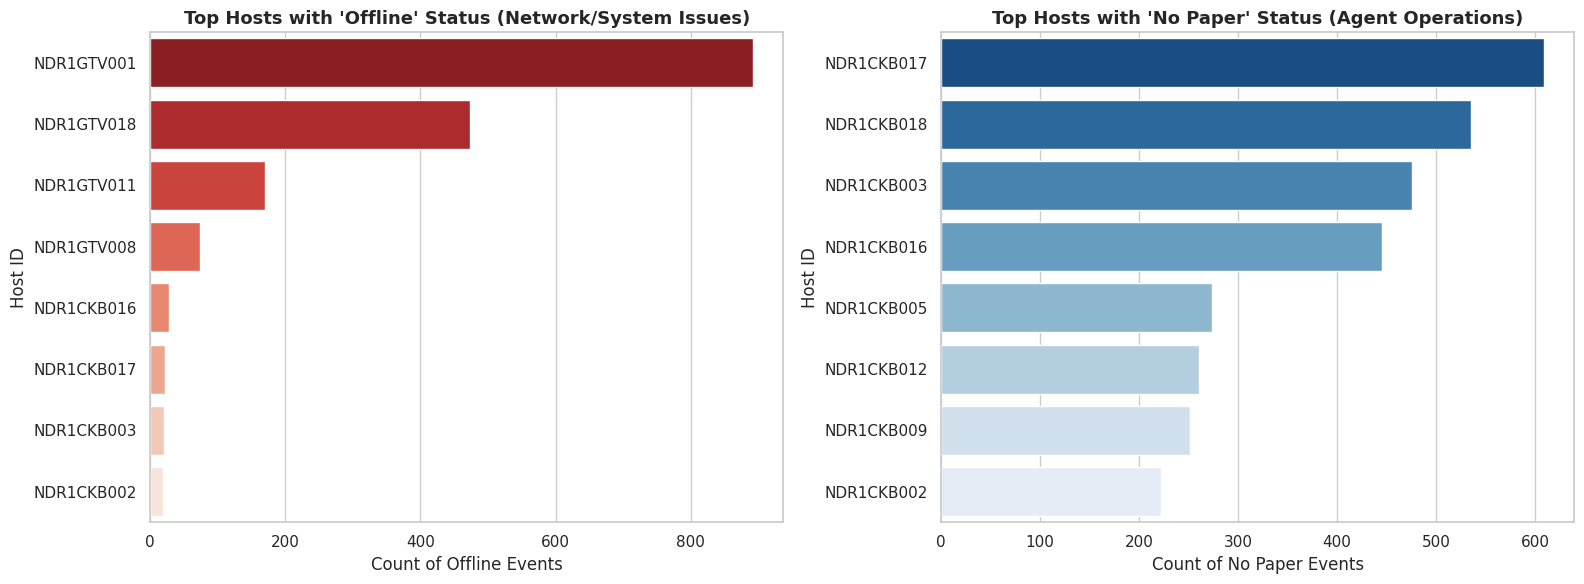

--- Detailed Counts per Host for 'Offline' vs 'No Paper' ---
New_Message  No Paper  Offline  Total
Host                                 
NDR1GTV001          0      892    892
NDR1GTV018          0      473    473
NDR1GTV011          0      170    170
NDR1GTV008          0       73     73
NDR1CKB016        445       28    473
NDR1CKB017        609       22    631
NDR1CKB003        476       20    496
NDR1CKB002        222       19    241
NDR1CKB005        274       18    292
NDR1CKB012        260       14    274


In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set figure size
plt.figure(figsize=(16, 6))

# ---------------------------------------------------------
# 1. Top Hosts for "Offline" Errors (Real Issues)
# ---------------------------------------------------------
plt.subplot(1, 2, 1)
offline_df = df[df['New_Message'] == 'Offline']
top_offline = offline_df['Host'].value_counts().head(8)

sns.barplot(
    x=top_offline.values, 
    y=top_offline.index, 
    hue=top_offline.index, 
    palette="Reds_r", 
    legend=False
)
plt.title("Top Hosts with 'Offline' Status (Network/System Issues)", fontsize=13, fontweight='bold')
plt.xlabel("Count of Offline Events")
plt.ylabel("Host ID")

# ---------------------------------------------------------
# 2. Top Hosts for "No Paper" (Operational End of Flights)
# ---------------------------------------------------------
plt.subplot(1, 2, 2)
nopaper_df = df[df['New_Message'] == 'No Paper']
top_nopaper = nopaper_df['Host'].value_counts().head(8)

sns.barplot(
    x=top_nopaper.values, 
    y=top_nopaper.index, 
    hue=top_nopaper.index, 
    palette="Blues_r", 
    legend=False
)
plt.title("Top Hosts with 'No Paper' Status (Agent Operations)", fontsize=13, fontweight='bold')
plt.xlabel("Count of No Paper Events")
plt.ylabel("Host ID")

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Summary Table Print (Groupby Analysis)
# ---------------------------------------------------------
print("--- Detailed Counts per Host for 'Offline' vs 'No Paper' ---")
filtered_df = df[df['New_Message'].isin(['Offline', 'No Paper'])]
pivot_summary = pd.crosstab(filtered_df['Host'], filtered_df['New_Message'])
pivot_summary['Total'] = pivot_summary['Offline'] + pivot_summary['No Paper']
print(pivot_summary.sort_values(by='Offline', ascending=False).head(10))

In [39]:
import pandas as pd
import numpy as np

# 1. Ensure 'Real_Date' is datetime and sort data chronologically per Host
if 'Timestamp' in df.columns:
    df['Real_Date'] = pd.to_datetime(df['Timestamp'], unit='s', errors='coerce')

df = df.sort_values(by=['Host', 'Real_Date']).reset_index(drop=True)

# ---------------------------------------------------------
# Feature 1: Error_Flag (1 for real hardware/network errors, 0 otherwise)
# ---------------------------------------------------------
real_errors = ['Offline', 'Power Off', 'Error', 'Unreachable', 'No Response...']
df['Error_Flag'] = df['New_Message'].apply(lambda x: 1 if x in real_errors else 0)

# ---------------------------------------------------------
# Feature 2: Is_Peak_Hour (1 for peak hours: 10, 11, 13, 14, 0 otherwise)
# ---------------------------------------------------------
df['Hour'] = df['Real_Date'].dt.hour
peak_hours = [10, 11, 13, 14]
df['Is_Peak_Hour'] = df['Hour'].apply(lambda x: 1 if x in peak_hours else 0)

# ---------------------------------------------------------
# Feature 3: Is_Weekend (1 for Saturday/Sunday, 0 for weekdays)
# ---------------------------------------------------------
df['DayOfWeek'] = df['Real_Date'].dt.dayofweek  # 5=Saturday, 6=Sunday
df['Is_Weekend'] = df['DayOfWeek'].apply(lambda x: 1 if x in [5, 6] else 0)

# ---------------------------------------------------------
# Feature 4: Time_Delta_Sec (Time difference in seconds between consecutive events on same Host)
# ---------------------------------------------------------
df['Time_Delta_Sec'] = df.groupby('Host')['Real_Date'].diff().dt.total_seconds()
# Fill NaN for the first event of each host with 0 or median
df['Time_Delta_Sec'] = df['Time_Delta_Sec'].fillna(0)

# ---------------------------------------------------------
# Verify the new features
# ---------------------------------------------------------
print("✅ Feature Engineering Completed Successfully!")
print(df[['Host', 'New_Message', 'Error_Flag', 'Is_Peak_Hour', 'Is_Weekend', 'Time_Delta_Sec']].head(10))

✅ Feature Engineering Completed Successfully!
         Host     New_Message  Error_Flag  Is_Peak_Hour  Is_Weekend  \
0  NDR1CKB001  No Response...           1             1           0   
1  NDR1CKB001          Online           0             0           0   
2  NDR1CKB001          Online           0             0           0   
3  NDR1CKB001          Online           0             0           0   
4  NDR1CKB001              OK           0             0           0   
5  NDR1CKB001         Offline           1             1           0   
6  NDR1CKB001          Online           0             1           0   
7  NDR1CKB001         Offline           1             0           1   
8  NDR1CKB001          Online           0             0           1   
9  NDR1CKB001         Offline           1             0           0   

   Time_Delta_Sec  
0             0.0  
1       9135058.0  
2             0.0  
3             0.0  
4             1.0  
5         22708.0  
6           189.0  
7        656

## 1️⃣ Option A: Classification (Predicting System Failures / Errors)


## test 1: 88% (365 prediction vrai from 535)

🎯 Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.92      0.93      2585
           1       0.63      0.66      0.65       522

    accuracy                           0.88      3107
   macro avg       0.78      0.79      0.79      3107
weighted avg       0.88      0.88      0.88      3107



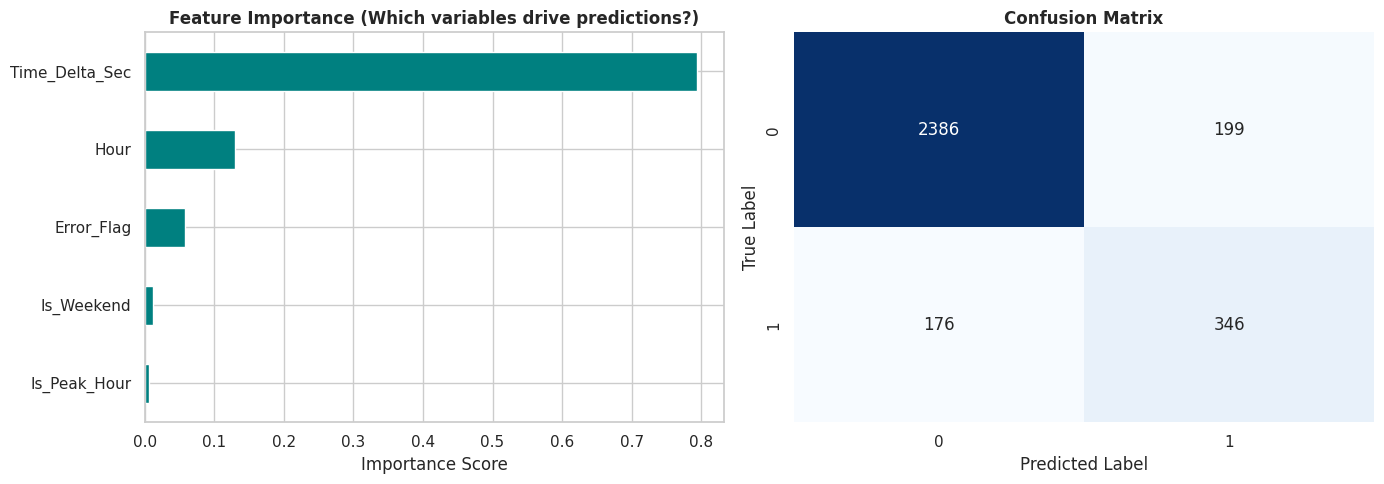

In [40]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Create Target Variable (Predict Next Event's Error Status)
# ---------------------------------------------------------
df['Target_Next_Error'] = df.groupby('Host')['Error_Flag'].shift(-1)

# Drop the last row per host since Target will be NaN
df_ml = df.dropna(subset=['Target_Next_Error']).copy()
df_ml['Target_Next_Error'] = df_ml['Target_Next_Error'].astype(int)

# ---------------------------------------------------------
# 2. Select Features (X) and Target (y)
# ---------------------------------------------------------
features = ['Hour', 'Is_Peak_Hour', 'Is_Weekend', 'Time_Delta_Sec', 'Error_Flag']
X = df_ml[features]
y = df_ml['Target_Next_Error']

# ---------------------------------------------------------
# 3. Train / Test Split (80% Train, 20% Test)
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ---------------------------------------------------------
# 4. Train Random Forest Model
# ---------------------------------------------------------
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model.fit(X_train, y_train)

# ---------------------------------------------------------
# 5. Model Evaluation
# ---------------------------------------------------------
y_pred = rf_model.predict(X_test)

print("🎯 Classification Report:")
print(classification_report(y_test, y_pred))

# ---------------------------------------------------------
# 6. Plot Feature Importance & Confusion Matrix
# ---------------------------------------------------------
plt.figure(figsize=(14, 5))

# Plot Feature Importance
plt.subplot(1, 2, 1)
importance = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=True)
importance.plot(kind='barh', color='teal')
plt.title("Feature Importance (Which variables drive predictions?)", fontweight='bold')
plt.xlabel("Importance Score")

# Plot Confusion Matrix
plt.subplot(1, 2, 2)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Confusion Matrix", fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

🎯 Classification Report (After Tuning & Rolling Features):
              precision    recall  f1-score   support

           0       0.97      0.98      0.98      2585
           1       0.90      0.85      0.87       522

    accuracy                           0.96      3107
   macro avg       0.93      0.91      0.92      3107
weighted avg       0.96      0.96      0.96      3107



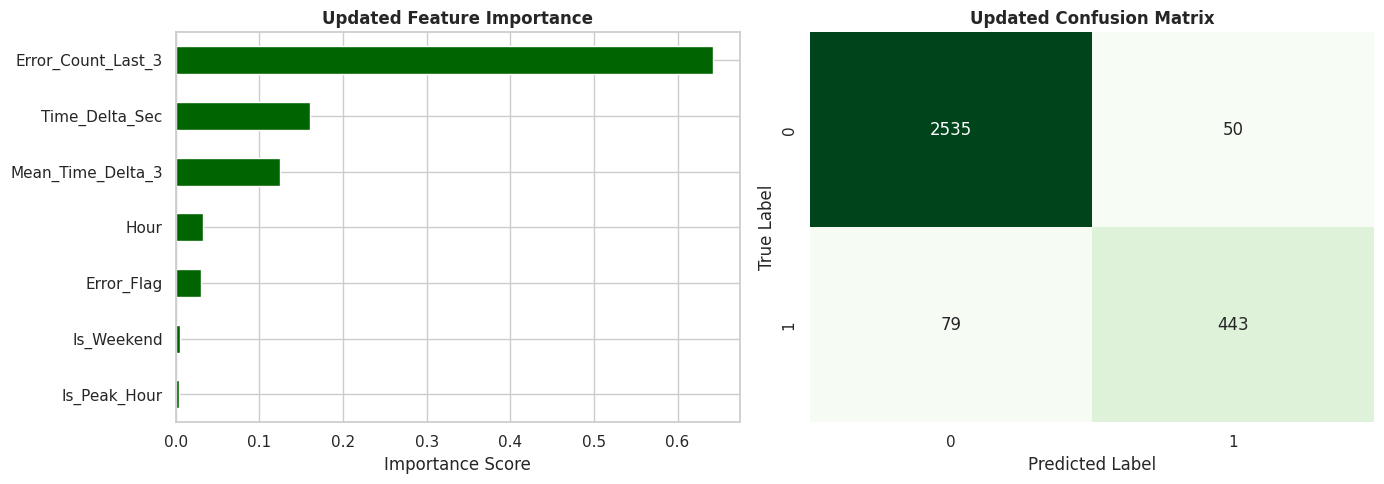

In [41]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Feature Engineering: Rolling / Lagged Features
# ---------------------------------------------------------
# Ensure chronological order
df = df.sort_values(by=['Host', 'Real_Date']).reset_index(drop=True)

# Rolling count of errors in the last 3 events per host
df['Error_Count_Last_3'] = df.groupby('Host')['Error_Flag'].transform(
    lambda x: x.shift(1).rolling(window=3, min_periods=1).sum()
).fillna(0)

# Rolling average of Time_Delta in the last 3 events per host
df['Mean_Time_Delta_3'] = df.groupby('Host')['Time_Delta_Sec'].transform(
    lambda x: x.shift(1).rolling(window=3, min_periods=1).mean()
).fillna(0)

# Target: Next Event's Error Status
df['Target_Next_Error'] = df.groupby('Host')['Error_Flag'].shift(-1)

# Clean dataset for ML
df_ml = df.dropna(subset=['Target_Next_Error']).copy()
df_ml['Target_Next_Error'] = df_ml['Target_Next_Error'].astype(int)

# ---------------------------------------------------------
# 2. Select Features & Split Data
# ---------------------------------------------------------
features = [
    'Hour', 'Is_Peak_Hour', 'Is_Weekend', 
    'Time_Delta_Sec', 'Error_Flag', 
    'Error_Count_Last_3', 'Mean_Time_Delta_3'
]

X = df_ml[features]
y = df_ml['Target_Next_Error']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ---------------------------------------------------------
# 3. Tuned Random Forest Classifier
# ---------------------------------------------------------
rf_tuned = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight={0: 1, 1: 2.5},  # Heavy focus on catching Errors (Class 1)
    random_state=42
)

rf_tuned.fit(X_train, y_train)

# ---------------------------------------------------------
# 4. Evaluation & Plots
# ---------------------------------------------------------
y_pred = rf_tuned.predict(X_test)

print("🎯 Classification Report (After Tuning & Rolling Features):")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(14, 5))

# Plot Updated Feature Importance
plt.subplot(1, 2, 1)
importance = pd.Series(rf_tuned.feature_importances_, index=features).sort_values(ascending=True)
importance.plot(kind='barh', color='darkgreen')
plt.title("Updated Feature Importance", fontweight='bold')
plt.xlabel("Importance Score")

# Plot Updated Confusion Matrix
plt.subplot(1, 2, 2)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False)
plt.title("Updated Confusion Matrix", fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

In [42]:
import joblib
import os

# Create a directory for artifacts
os.makedirs('model_artifacts', exist_ok=True)

# 1. Save the trained tuned model
joblib.dump(rf_tuned, 'model_artifacts/predictive_maintenance_rf.pkl')

# 2. Save the features list
joblib.dump(features, 'model_artifacts/model_features.pkl')

print("✅ Model and artifacts saved successfully in 'model_artifacts/'!")

✅ Model and artifacts saved successfully in 'model_artifacts/'!
